In [3]:
import os
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
import gliders as gl
from astropy.wcs import WCS
from astropy.table import Table

from build.lib.gliders.utils import normalize_data
from gliders.utils import sigma_clipping, grow_mask, get_profile_from_border, normalize_data
from gliders.artifacts import detect_artifacts, get_artifact_flag, clean_artifacts, detect_and_clean_artifacts
from gliders.noise_pusher import diminish_noise_level, show_all_methods
from scipy.stats import norm
from scipy.signal import convolve2d
from astropy.convolution import Gaussian2DKernel

def extract_band_data(hdu_list, verbose=True, bands_to_analyze = ['r']):
    all_bands = {}
    all_img_diffs = {}
    all_img_areas = {}
    all_weights = {}
    all_wgh_diffs = {}
    all_wgh_areas = {}
    ref_hdu = None
    for hdu in hdu_list:
        try:
            header = hdu._header
            if verbose:
                print(header)
            band = header.get("BAND")
            if band not in bands_to_analyze: continue
            image_type = header.get("IMAGETYP")
            imagew = header.get("IMAGEW")
            imageh = header.get("IMAGEH")

            if band is None or image_type is None or imagew is None or imageh is None:
                continue  # Skip if essential header info is missing

            img_dim_diff = abs(imagew - imageh)
            img_area = imagew * imageh

            if image_type == "image":
                if band not in all_bands or img_area > all_img_areas[band] or (img_area == all_img_areas[band] and img_dim_diff < all_img_diffs[band]):
                    all_bands[band] = hdu.copy().data
                    all_img_areas[band] = img_area
                    all_img_diffs[band] = img_dim_diff
                    ref_hdu = hdu.header

            elif image_type == "invvar":
                w_map = hdu.copy().data
                w_map[w_map == 0] += 1  # Avoid division by zero
                weight = 1 / np.sqrt(w_map)
                if band not in all_weights or img_area > all_wgh_areas[band] or (img_area == all_wgh_areas[band] and img_dim_diff < all_wgh_diffs[band]):
                    all_weights[band] = weight
                    all_wgh_areas[band] = img_area
                    all_wgh_diffs[band] = img_dim_diff

        except Exception as e:
            print(f"Skipped HDU due to error: {e}")

    return all_bands, all_weights, ref_hdu

file_dir = "C:\\Astrostuff\\PhD\\Data\\DESI FITS\\DESI_dwarf_AGN_fits"
artif_file = "D:/Astrostuff/PhD/Data/My_Data/images_with_artifacts_DESI.csv"
artif_catalog = Table.read(artif_file, format = "csv")

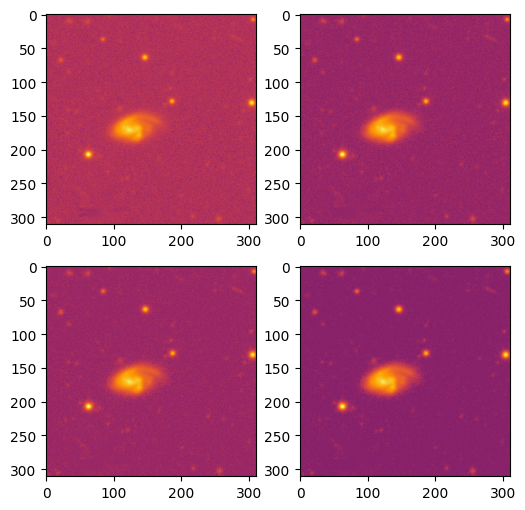

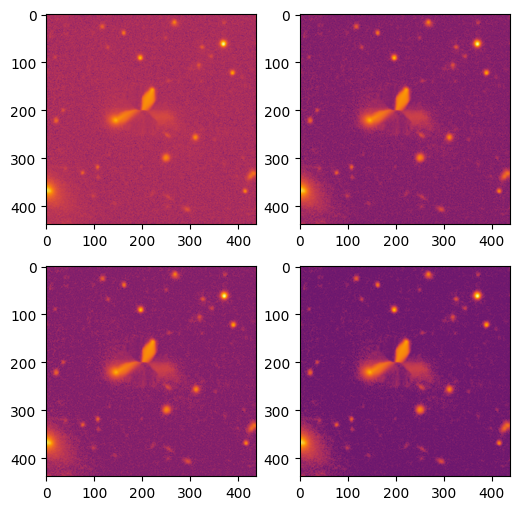

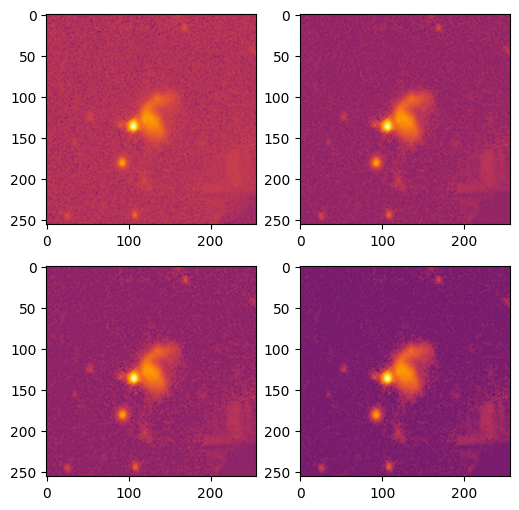

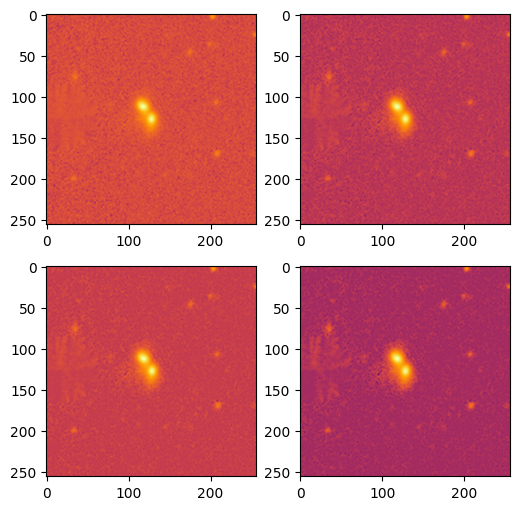

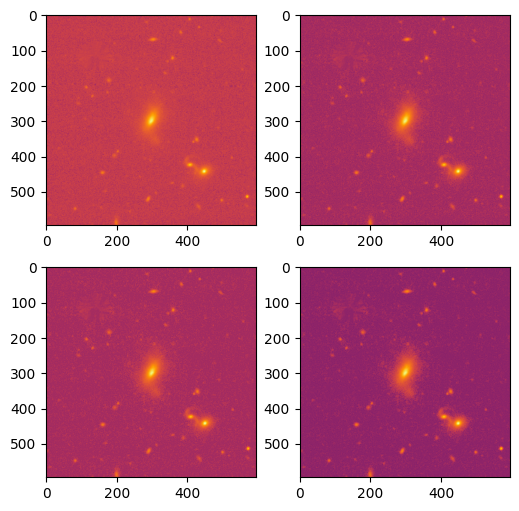

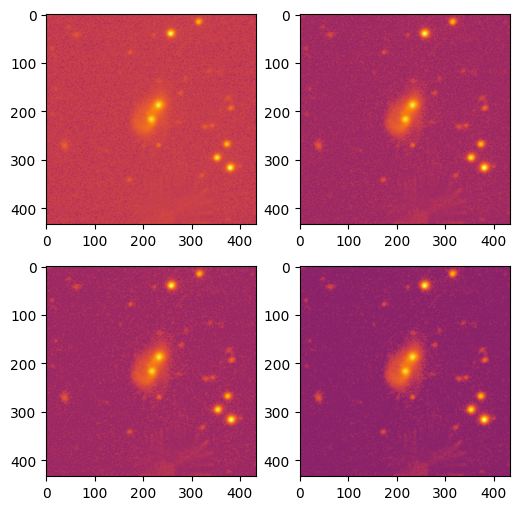

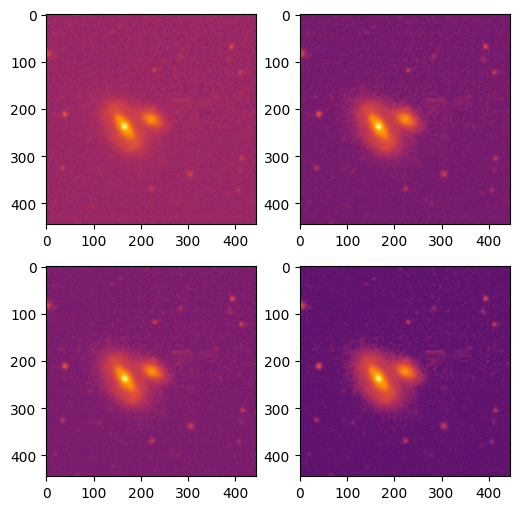

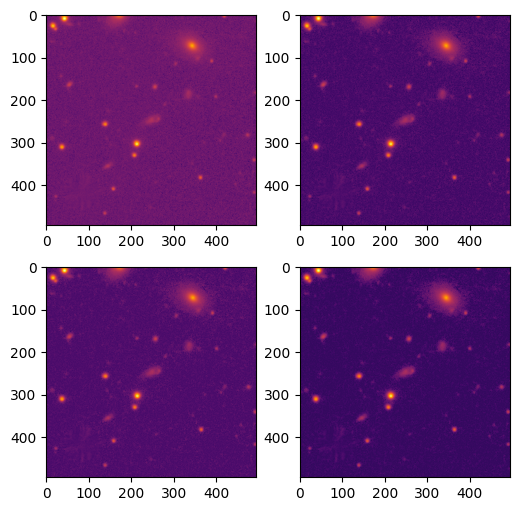

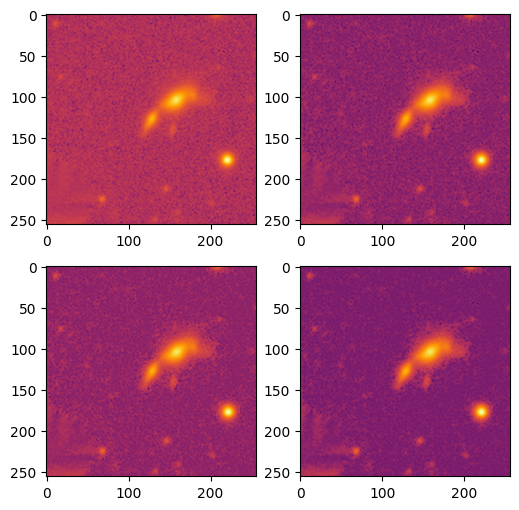

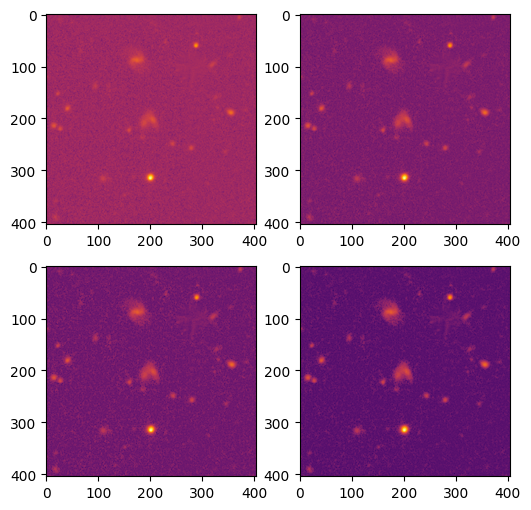

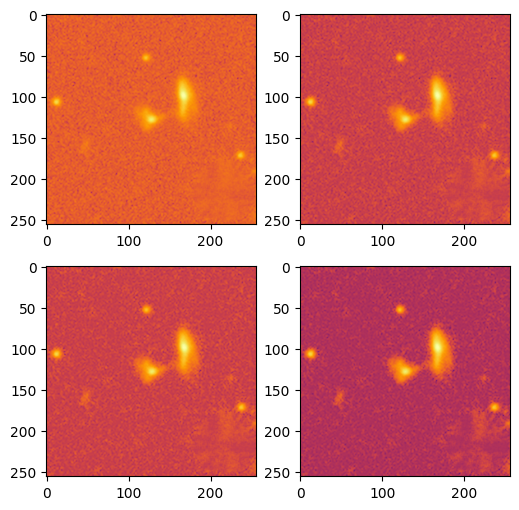

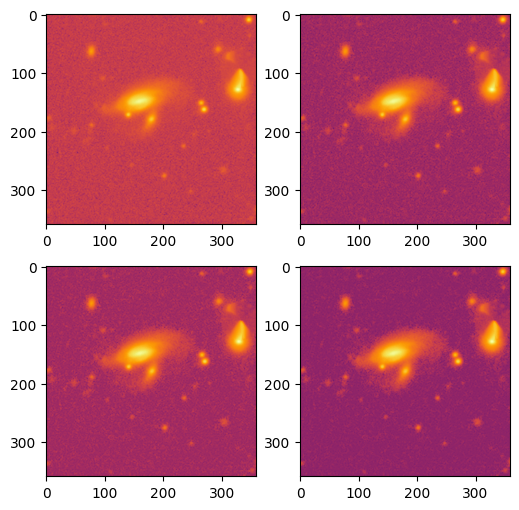

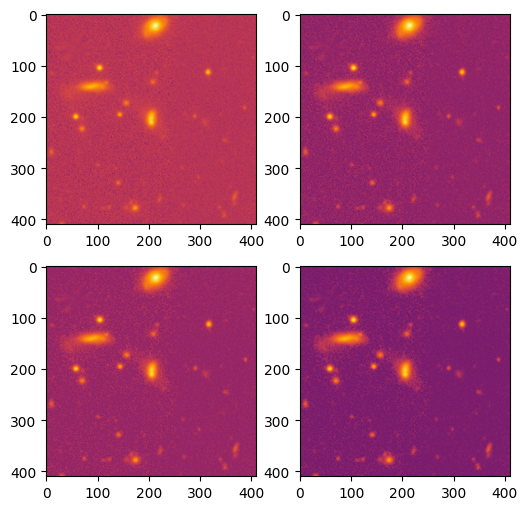

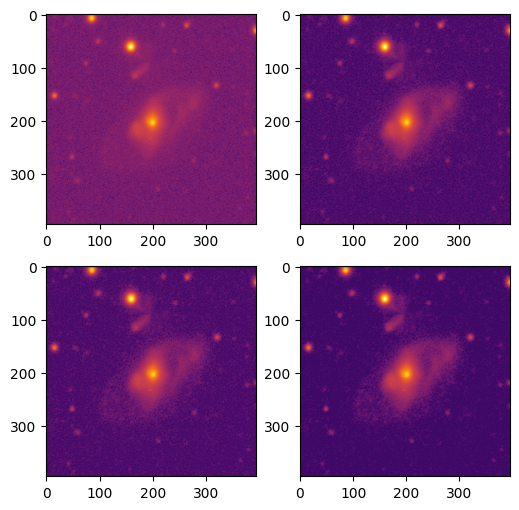

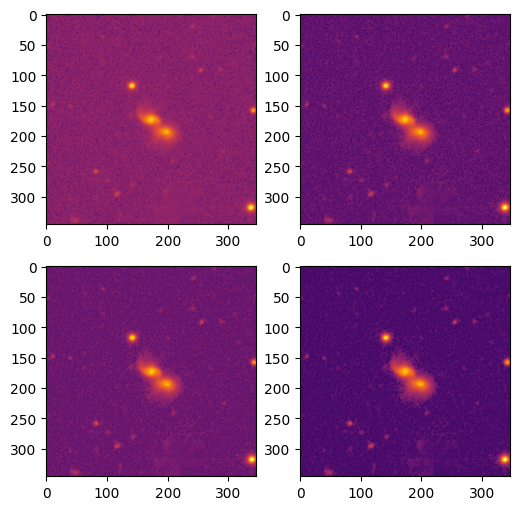

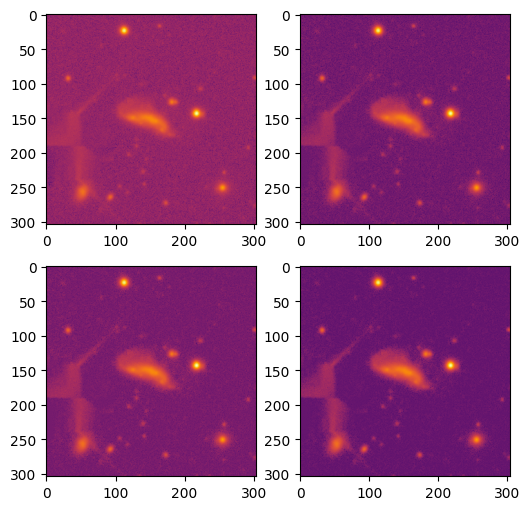

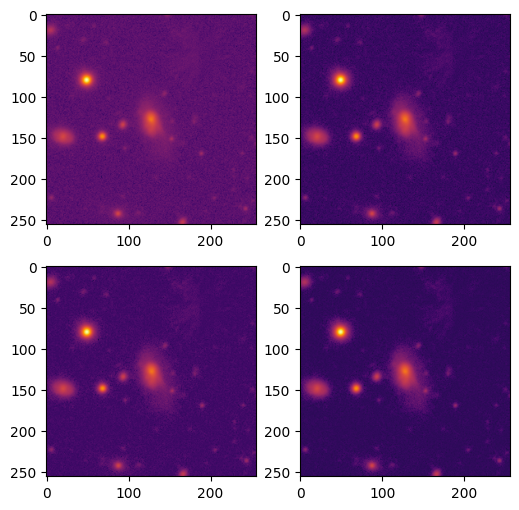

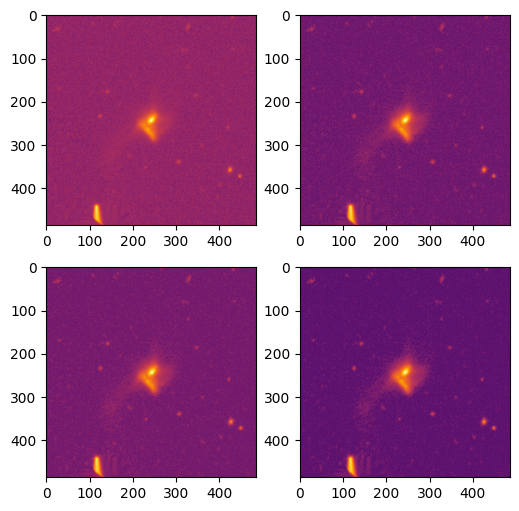

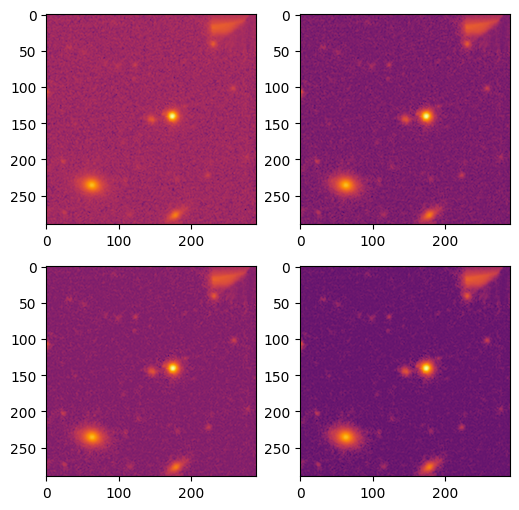

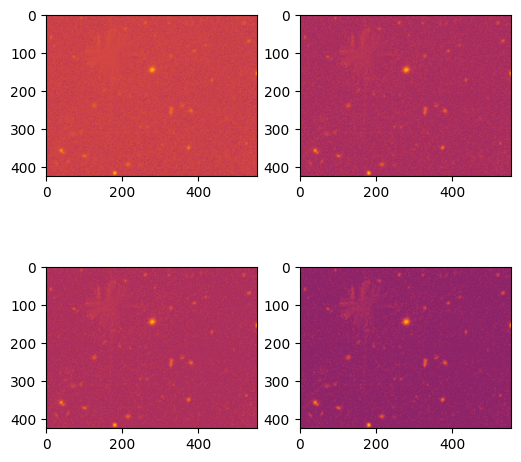

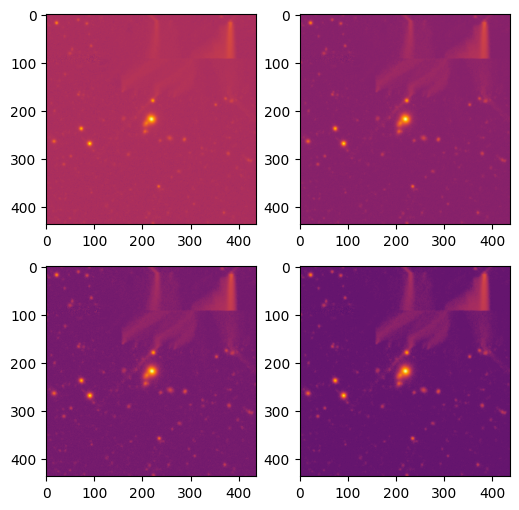

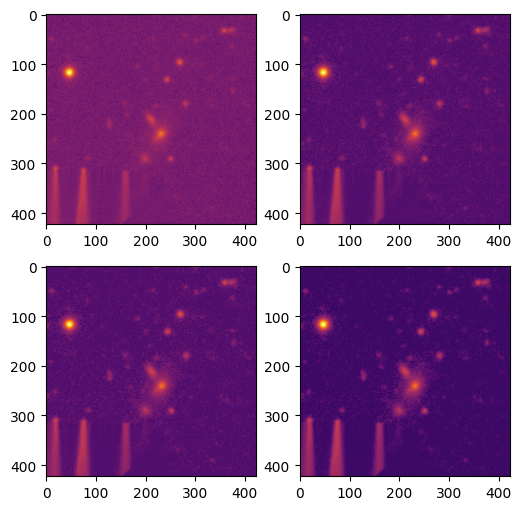

In [7]:
for ii, object_info in enumerate(artif_catalog):
# try:
    object_id = object_info[0]
    obj_coords = (object_info[1],object_info[2])
    redshift = object_info[3]
    bands = ['r','g']
    file_name = f"{object_id}_{"".join(bands)}.fits"
    sources_name = f"{object_id}_sources.fits"

    file_path = os.path.join(file_dir, file_name)
    sources_path = os.path.join(file_dir, sources_name)
    with fits.open(file_path) as hdu_list:
        # hdu_list.info()
        all_bands, all_weights, ref_header = extract_band_data(hdu_list, verbose=False, bands_to_analyze=bands)

    from astropy.table import Table
    with fits.open(sources_path) as hdul:
        data = hdul[1].data
        as_table = Table(data)
    wcs = WCS(ref_header)
    tractor_x_pix, tractor_y_pix = wcs.all_world2pix(as_table['ra'], as_table['dec'], 0)  # origin=0 for Python indexing
    source_x_pix, source_y_pix = wcs.all_world2pix(obj_coords[0], obj_coords[1], 0)  # origin=0 for Python indexing
    source_pos = (np.round(source_x_pix), np.round(source_y_pix))
    as_table['xcentroid'] = tractor_x_pix
    as_table['ycentroid'] = tractor_y_pix
    phot_sources = as_table['type','xcentroid','ycentroid']
    image = all_bands['r']


    if obj_coords[1] > 32.375:
        pix_scale = 1.72
    else:
        pix_scale = 1

    artifacts_segmap = detect_artifacts(image, npixels_artifact=100, delta_slope_threshold=2.7, segment_slack=5,
                         hi_pass_threshold=1)
    artifacts_mask = artifacts_segmap.make_source_mask()
    segment_slack = 15
    sigmas = 10
    test_bleed = 30
    bleeding_factor = 0.4
    noise_mean, noise_std = sigma_clipping(image)
    noise_lvl = noise_mean + sigmas * noise_std
    clean_image, clean_mask = clean_artifacts(image, artifacts_segmap, bleeding_factor = 1.5, interpolation_radius = 2, pix_scale = pix_scale)
    clean_image_noise_mean, clean_image_noise_std = sigma_clipping(clean_image)

    norm_plus = 0.0001
    pushed_a = diminish_noise_level(clean_image, method = "simple", kernel = None, logit_alpha = 1.0)
    pushed_b = diminish_noise_level(clean_image, method = "logit", kernel = None, logit_alpha = 1.0)
    pushed_c = diminish_noise_level(clean_image, method = "layers", kernel = None, logit_alpha = 1.0)

    clean_image_norm = normalize_data(clean_image) + norm_plus
    pushed_norm_a = normalize_data(pushed_a) + norm_plus
    pushed_norm_b = normalize_data(pushed_b) + norm_plus
    pushed_norm_c = normalize_data(pushed_c) + norm_plus

    pushed_image_a_flat = pushed_norm_a.flatten()
    pushed_image_b_flat = pushed_norm_b.flatten()
    pushed_image_c_flat = pushed_norm_c.flatten()

    clean_image_norm_noise = sigma_clipping(clean_image_norm)
    lim = clean_image_norm_noise[0] + 5*clean_image_norm_noise[1]
    clean_image_flat = clean_image_norm.flatten()
    clean_image_flat = clean_image_flat[clean_image_flat<lim]
    # lim = lim*0.12
    pushed_image_a_flat = pushed_image_a_flat[pushed_image_a_flat<lim]
    pushed_image_b_flat = pushed_image_b_flat[pushed_image_b_flat<lim]
    pushed_image_c_flat = pushed_image_c_flat[pushed_image_c_flat<lim]
    fig, ax = plt.subplots(2, 2, figsize=(6, 6))
    ax[0,0].imshow(clean_image_norm, norm = "log", cmap = "inferno") #, bins = 30)
    ax[0,1].imshow(pushed_norm_a, norm = "log", cmap = "inferno") #, bins = 30)
    ax[1,0].imshow(pushed_norm_b, norm = "log", cmap = "inferno") #, bins = 30)
    ax[1,1].imshow(pushed_norm_c, norm = "log", cmap = "inferno") #, bins = 30)
    # ax[0,0].hist(clean_image_flat, bins = 60)
    # ax[0,1].hist(pushed_image_a_flat, bins = 60)
    # ax[1,0].hist(pushed_image_b_flat, bins = 60)
    # ax[1,1].hist(pushed_image_c_flat, bins = 60)
    plt.show()
    if ii > 20:
        break
